# Geospatial Vegetation Monitor
Compares vegetation (NDVI) at one location between **two dates** using Sentinel-2 satellite imagery, and shows the result on a map.

**Inputs** : `data/study_area.geojson` (location) and `config.json` (dates, buffer size, thresholds).
**Outputs** are saved to `outputs/`.

**Pipeline:** GeoJSON polygon (AOI) → Sentinel-2 red + NIR for date 1 and date 2 → NDVI → difference → map.

## 1. Setup and inputs

In [1]:
import json
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import folium
from pathlib import Path
import helpers as h

cfg = h.load_config("config.json")
out = Path(cfg["output_dir"]); out.mkdir(exist_ok=True)
print(json.dumps(cfg, indent=2))

{
  "study_area_file": "data/study_area.geojson",
  "buffer_m": 2000,
  "date_1": {
    "start": "2025-01-01",
    "end": "2025-02-28"
  },
  "date_2": {
    "start": "2026-01-01",
    "end": "2026-02-28"
  },
  "max_cloud_percent": 20,
  "data_source": "synthetic",
  "change_threshold": 0.1,
  "diff_display_range": 0.3,
  "output_dir": "outputs"
}


## 2. Vector data: study area (GeoJSON) and CRS
The GeoJSON holds a **Polygon** (`[lon, lat]`, EPSG:4326, degrees). Distances and areas need a **metric CRS**, so the work is done in the local UTM zone and then converted back to lat/lon.

In [2]:
aoi_ll, aoi_utm = h.build_aoi(cfg["study_area_file"], cfg["buffer_m"])
print("Input CRS:       EPSG:4326 (lon/lat degrees)")
print("Working CRS:    ", aoi_utm.crs.to_string())
print(f"AOI area:        {aoi_utm.area.iloc[0] / 1e6:.2f} km²")
aoi_ll.to_file(out / "aoi_polygon.geojson", driver="GeoJSON")
aoi_ll

Input CRS:       EPSG:4326 (lon/lat degrees)
Working CRS:     EPSG:32639
AOI area:        2.63 km²


,geometry
0,"POLYGON ((51.55736 24.95424, 51.55531 24.94193..."


## 3. Raster data: Sentinel-2 red (B04) and near-infrared (B08)
For each date window the least cloudy scene is picked and clipped to the AOI. Date 2 reuses the same satellite tile as date 1 so both rasters line up pixel for pixel.
Set `"data_source": "synthetic"` in `config.json` to test the notebook offline with fake data.

In [3]:
if cfg["data_source"] == "synthetic":
    red1, nir1, meta1 = h.get_scene_synthetic(aoi_utm, loss=False)
    red2, nir2, meta2 = h.get_scene_synthetic(aoi_utm, loss=True)
else:
    d1, d2 = cfg["date_1"], cfg["date_2"]
    red1, nir1, meta1 = h.get_scene_real(aoi_ll, d1["start"], d1["end"], cfg["max_cloud_percent"])
    red2, nir2, meta2 = h.get_scene_real(aoi_ll, d2["start"], d2["end"], cfg["max_cloud_percent"], tile=meta1["tile"])
    red2, nir2 = red2.rio.reproject_match(red1), nir2.rio.reproject_match(red1)   # guarantee identical grid

print("Date 1:", meta1)
print("Date 2:", meta2)
print("Raster CRS:", red1.rio.crs, "| shape:", red1.shape, "| pixel size (m):", red1.rio.resolution())

Date 1: {'scene_id': 'synthetic', 'date': 'synthetic-base', 'cloud_percent': 0.0, 'tile': None}
Date 2: {'scene_id': 'synthetic', 'date': 'synthetic-loss', 'cloud_percent': 0.0, 'tile': None}
Raster CRS: EPSG:32639 | shape: (200, 200) | pixel size (m): (16.316117154034767, -16.31611715403418)


## 4. Vegetation index: NDVI
`NDVI = (NIR − Red) / (NIR + Red)`. Roughly: below 0 water, ~0.05 desert/bare soil, 0.2-0.4 sparse vegetation, 0.6+ dense vegetation. This area is arid, so expect low values and look at the *change* rather than the absolute level.

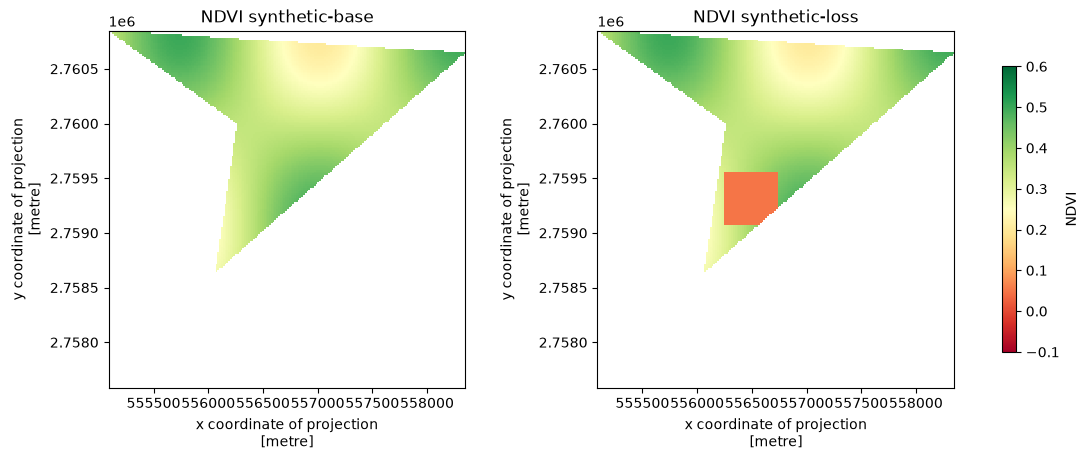

In [4]:
ndvi1, ndvi2 = h.ndvi(red1, nir1), h.ndvi(red2, nir2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for a, da, m in zip(ax, (ndvi1, ndvi2), (meta1, meta2)):
    im = da.plot(ax=a, cmap="RdYlGn", vmin=-0.1, vmax=0.6, add_colorbar=False)
    a.set_title(f"NDVI {m['date']}"); a.set_aspect("equal")
fig.colorbar(im, ax=ax, shrink=0.8, label="NDVI")
fig.savefig(out / "ndvi_two_dates.png", dpi=150)
plt.show()

## 5. Temporal comparison
`change = NDVI(date 2) − NDVI(date 1)`. Pixels changing by more than `change_threshold` count as loss or gain.

In [5]:
diff = ndvi2 - ndvi1
t = cfg["change_threshold"]
valid = int(diff.notnull().sum())
pix_km2 = abs(np.prod(diff.rio.resolution())) / 1e6

summary = pd.DataFrame({
    "metric": ["Date 1", "Date 2", "Mean NDVI date 1", "Mean NDVI date 2", "Mean change",
               f"Loss area km² (change < -{t})", f"Gain area km² (change > {t})", "Valid area km²"],
    "value": [meta1["date"], meta2["date"], round(float(ndvi1.mean()), 3), round(float(ndvi2.mean()), 3),
              round(float(diff.mean()), 3), round(float((diff < -t).sum()) * pix_km2, 3),
              round(float((diff > t).sum()) * pix_km2, 3), round(valid * pix_km2, 3)],
})
summary.to_csv(out / "summary.csv", index=False)
summary

,metric,value
0,Date 1,synthetic-base
1,Date 2,synthetic-loss
2,Mean NDVI date 1,0.357
3,Mean NDVI date 2,0.329
4,Mean change,-0.028
5,Loss area km² (change < -0.1),0.226
6,Gain area km² (change > 0.1),0.0
7,Valid area km²,2.631


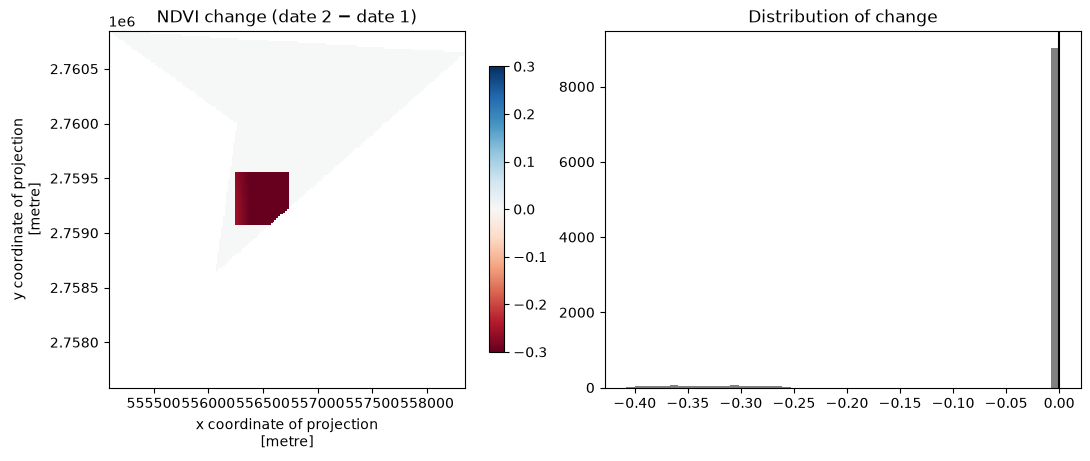

In [6]:
r = cfg["diff_display_range"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
im = diff.plot(ax=ax[0], cmap="RdBu", vmin=-r, vmax=r, add_colorbar=False)
ax[0].set_title("NDVI change (date 2 − date 1)"); ax[0].set_aspect("equal")
fig.colorbar(im, ax=ax[0], shrink=0.8)
diff.plot.hist(ax=ax[1], bins=50, color="grey"); ax[1].axvline(0, color="k")
ax[1].set_title("Distribution of change")
fig.savefig(out / "ndvi_change.png", dpi=150)
plt.show()

## 6. Interactive map
Rasters are reprojected to EPSG:4326 for the web map. Use the layer switch (top right) to toggle NDVI for each date and the change layer.

C:\Users\Nidhin\AppData\Local\Temp\ipykernel_45900\2480345442.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  lon, lat = aoi_ll.centroid.x.iloc[0], aoi_ll.centroid.y.iloc[0]



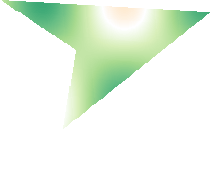
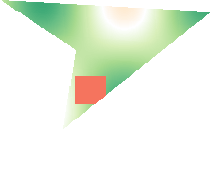
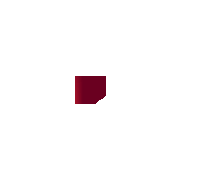

In [7]:
lon, lat = aoi_ll.centroid.x.iloc[0], aoi_ll.centroid.y.iloc[0]
m = folium.Map(location=[lat, lon], zoom_start=14, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Satellite").add_to(m)

layers = [(ndvi1, f"NDVI {meta1['date']}", -0.1, 0.6, "RdYlGn", False),
          (ndvi2, f"NDVI {meta2['date']}", -0.1, 0.6, "RdYlGn", False),
          (diff, "NDVI change", -r, r, "RdBu", True)]
for da, name, vmin, vmax, cmap, show in layers:
    img, bounds = h.to_overlay(da, vmin, vmax, cmap)
    folium.raster_layers.ImageOverlay(img, bounds=bounds, name=name, opacity=0.75, show=show).add_to(m)

folium.GeoJson(aoi_ll.__geo_interface__, name="AOI",
               style_function=lambda f: {"color": "black", "fill": False, "weight": 2}).add_to(m)
folium.Marker([lat, lon], tooltip="Study area centroid").add_to(m)
folium.LayerControl().add_to(m)
m.save(out / "ndvi_change_map.html")
m

## 7. Reading the result
- **Red** on the change layer = NDVI fell (less vegetation or drier ground). **Blue** = NDVI rose (more vegetation).
- Always check the scene dates and cloud % printed in section 3. Different seasons or leftover cloud/shadow create fake change.
- In arid areas small NDVI changes can come from soil moisture or irrigation, so use `summary.csv` and the map together.